Problem Statement

Businesses often collect large amounts of customer data, but identifying meaningful customer groups from this data is challenging. Without proper analysis, it becomes difficult to understand customer purchasing behavior, create targeted marketing strategies, and improve customer satisfaction. This project aims to analyze customer data and segment customers based on their Annual Income and Spending Score using Exploratory Data Analysis (EDA) and K-Means Clustering.

Objective

- To analyze the customer dataset using Python.
- To perform Exploratory Data Analysis (EDA) for better understanding of the data.
- To visualize customer characteristics using charts and graphs.
- To apply the K-Means Clustering algorithm to group similar customers.
- To identify different customer segments that can help businesses make informed marketing and business decisions.

In [ ]:
import os
print(os.listdir())

['.config', 'sample_data']


In [ ]:
import pandas as pd

df = pd.read_csv("/Mall_Customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income(k$),Spending Score(1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
df.shape

(10, 5)

In [ ]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income(k$)',
       'Spending Score(1-100)'],
      dtype='object')

In [ ]:
df.describe()

,CustomerID,Age,Annual Income(k$),Spending Score(1-100)
count,10.00000,10.000000,10.000000,10.000000
mean,5.50000,28.800000,17.000000,49.400000
std,3.02765,13.464356,1.490712,35.094159
min,1.00000,19.000000,15.000000,3.000000
25%,3.25000,21.250000,16.000000,14.250000
50%,5.50000,23.000000,17.000000,56.000000
75%,7.75000,30.750000,18.000000,76.750000
max,10.00000,64.000000,19.000000,94.000000


In [ ]:
df.dtypes

,0
CustomerID,int64
Gender,object
Age,int64
Annual Income(k$),int64
Spending Score(1-100),int64


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.tail()

,CustomerID,Gender,Age,Annual Income(k$),Spending Score(1-100)
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [ ]:
import matplotlib.pyplot as plt

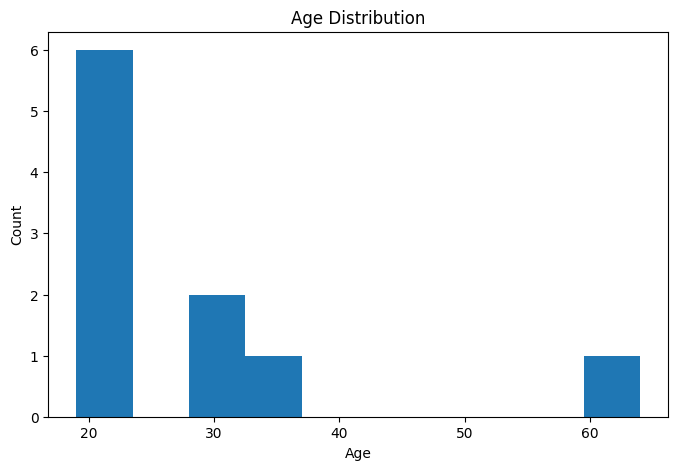

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df['Age'], bins=10)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

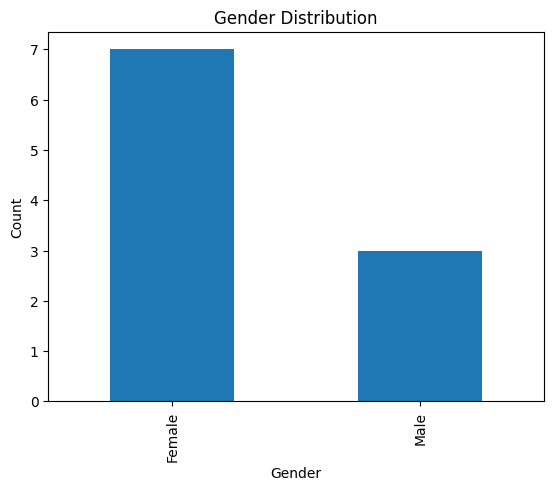

In [ ]:
df['Gender'].value_counts().plot(kind='bar')
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

In [ ]:
print(df.columns)

Index(['CustomerID', 'Gender', 'Age', 'Annual Income(k$)',
       'Spending Score(1-100)'],
      dtype='object')


In [ ]:
for col in df.columns:
    print(repr(col))

'CustomerID'
'Gender'
'Age'
'Annual Income(k$)'
'Spending Score(1-100)'


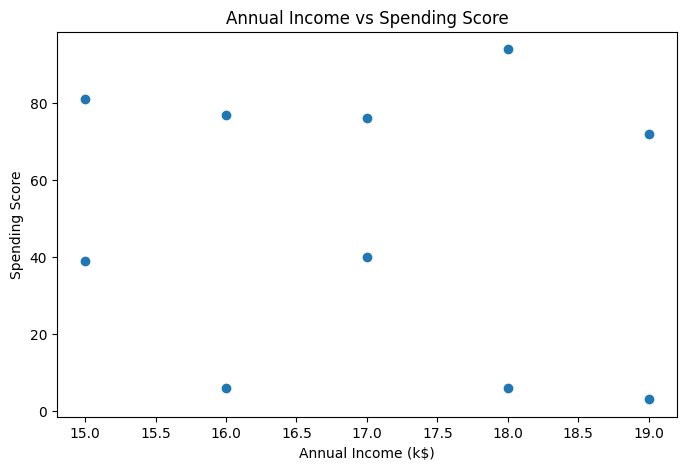

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.scatter(df["Annual Income(k$)"], df["Spending Score(1-100)"])
plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.show()

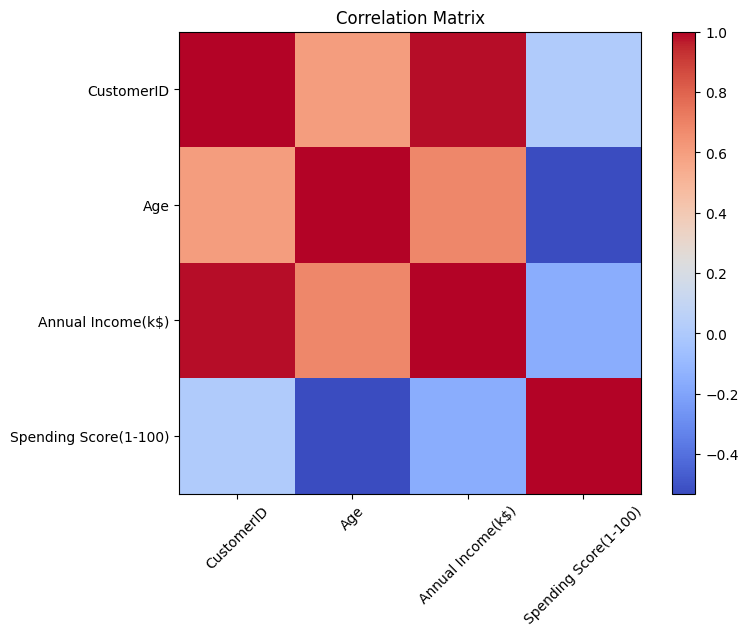

In [ ]:
numeric_df = df.select_dtypes(include=['number'])

plt.figure(figsize=(8,6))
plt.imshow(numeric_df.corr(), cmap='coolwarm')
plt.colorbar()

plt.xticks(range(len(numeric_df.columns)), numeric_df.columns, rotation=45)
plt.yticks(range(len(numeric_df.columns)), numeric_df.columns)

plt.title("Correlation Matrix")
plt.show()

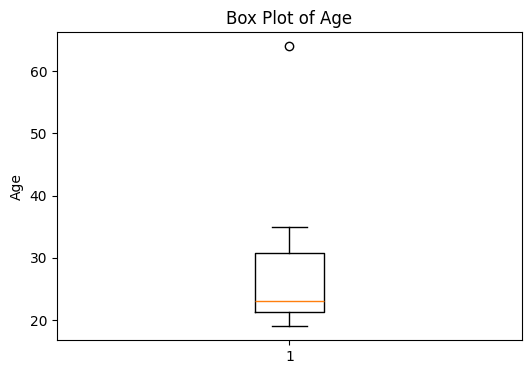

In [ ]:
plt.figure(figsize=(6,4))
plt.boxplot(df["Age"])
plt.title("Box Plot of Age")
plt.ylabel("Age")
plt.show()

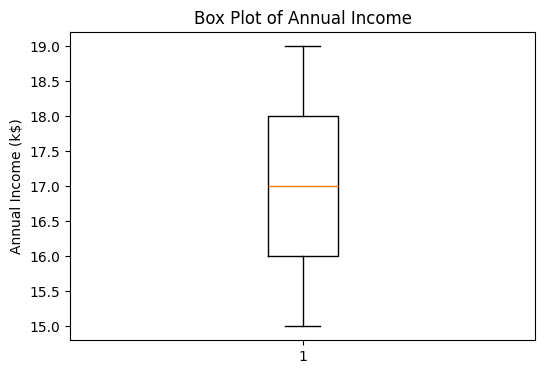

In [ ]:
plt.figure(figsize=(6,4))
plt.boxplot(df["Annual Income(k$)"])
plt.title("Box Plot of Annual Income")
plt.ylabel("Annual Income (k$)")
plt.show()

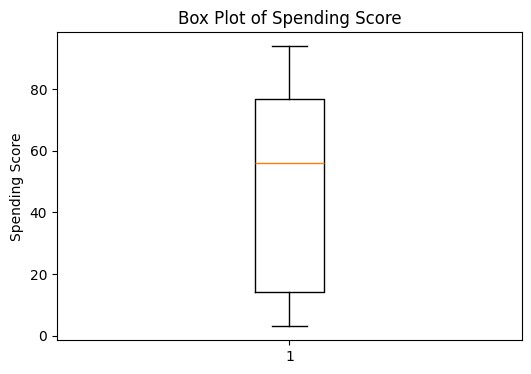

In [ ]:
plt.figure(figsize=(6,4))
plt.boxplot(df["Spending Score(1-100)"])
plt.title("Box Plot of Spending Score")
plt.ylabel("Spending Score")
plt.show()

In [ ]:
from sklearn.cluster import KMeans

In [ ]:
X = df[['Annual Income(k$)', 'Spending Score(1-100)']]

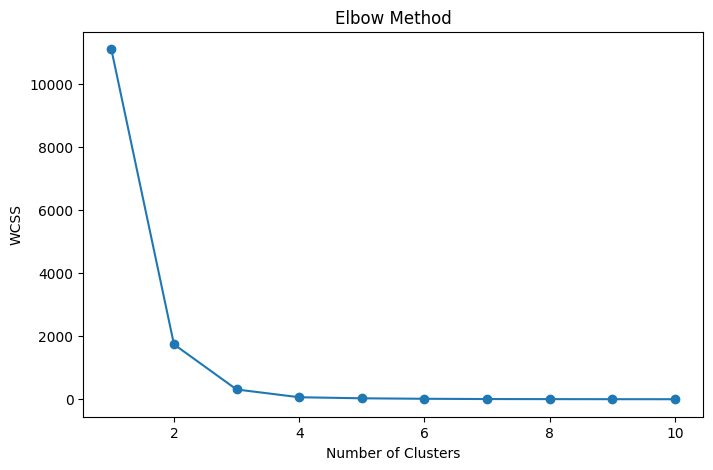

In [ ]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(1,11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X)

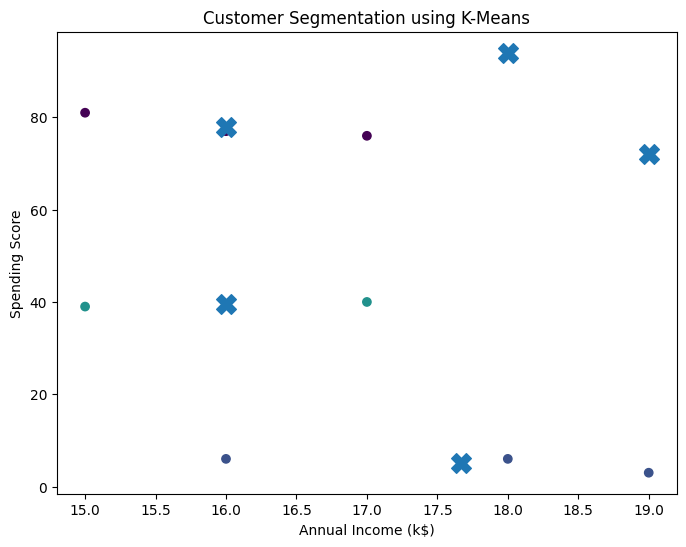

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(df['Annual Income(k$)'],
            df['Spending Score(1-100)'],
            c=df['Cluster'])

plt.scatter(kmeans.cluster_centers_[:,0],
            kmeans.cluster_centers_[:,1],
            s=200,
            marker='X')

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')
plt.show()

In [ ]:
df.to_csv("Mall_Customers_Clustered.csv", index=False)

In [ ]:
from google.colab import files
files.download("Mall_Customers_Clustered.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Conclusion

This project analyzed customer data using Exploratory Data Analysis (EDA) and K-Means Clustering. The dataset was explored using statistical summaries and visualizations to understand customer characteristics. The Elbow Method was used to determine the optimal number of clusters, and K-Means clustering grouped customers based on their Annual Income and Spending Score. The results help identify different customer segments, which can be useful for targeted marketing, improving customer satisfaction, and making better business decisions.